# 2. Erronka – Smart Environment AI: Mundakako airearen kalitatea

**Modulua:** Adimen Artifizialerako Programazioa · **Zikloa:** IA eta Big Data (FP Santurtzi)

## 1. Sarrera eta testuingurua

Erronka honetan **Bizkaiko Foru Aldundiaren** airearen kalitatearen monitorizazio sareko estazio baten datuekin lan egingo dugu: **Mundakako** estazioarekin. Estazioak egunero neurtzen ditu hainbat kutsatzaile (NO, NOX, NO2, O3, PM10 eta PM2,5), µg/m³ unitatetan.

Gure helburua **Smart Environment AI** soluzio baten oinarria prestatzea da: datuak aztertu (EDA), garbitu eta aurreprozesatzeko *pipeline* bat sortu, gero eredu bat entrenatzeko eta ondoren **Jetson Nano** gailuan exekutatzeko.

Koaderno honetan hauek egingo ditugu:

1. Datuak kargatu eta egitura aztertu.
2. Azterketa esploratzailea (EDA): estatistikak, banaketak, denbora-bilakaera eta korrelazioak.
3. Garbiketa, balio hutsen tratamendua eta *outlier*-en azterketa.
4. Ezaugarri tenporalak sortu (`Month`, `DayOfWeek`, `DayOfYear`).
5. Aldagaiak eraldatu (estandarizazioa, *one-hot* eta PCA), Scikit-Learn *Pipeline* bat sortu eredu sinple batekin eta PCA-ren eragina aztertu.
6. *Pipeline*-a datu berriekin probatu eta `joblib` bidez gorde (`.pkl`).
7. Entrenamendurako datu-multzo garbia sortu eta egindako eragiketa guztiak dokumentatu.

## 2. Datuen karga eta egitura

CSV fitxategia `;` bereizlearekin eta `latin1` kodeketarekin irakurtzen dugu (`µ` ikurra egoki ager dadin). Datak `DD/MM/YYYY` formatuan datoz, beraz formatua zehaztu behar dugu `pd.to_datetime` erabiltzean. Gero kronologikoki ordenatuko ditugu, fitxategian atzekoz aurrera baitaude (azken eguna lehenengo).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Grafikoen konfigurazioa
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Datuen karga (bereizlea ';' eta kodeketa 'latin1')
df = pd.read_csv('MUNDAKA.csv', sep=';', encoding='latin1')

# 2. Datak datetime formatura pasa (DD/MM/YYYY) eta ordena kronologikoa
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df = df.sort_values('Date').reset_index(drop=True)

# 3. Egituraren laburpena
print("--- DATAFRAME INFO ---")
print(df.info())
print("\n--- BALIO HUTSAK ZUTABEKO ---")
print(df.isnull().sum())
print("\n--- ESTATISTIKA DESKRIBATZAILEAK ---")
display(df.describe())

--- DATAFRAME INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           306 non-null    datetime64[us]
 1   NO (µg/m3)     302 non-null    float64       
 2   NOX (µg/m3)    302 non-null    float64       
 3   NO2 (µg/m3)    302 non-null    float64       
 4   O3 (µg/m3)     304 non-null    float64       
 5   O3 8h (µg/m3)  211 non-null    float64       
 6   PM10 (µg/m3)   257 non-null    float64       
 7   PM2,5 (µg/m3)  304 non-null    float64       
dtypes: datetime64[us](1), float64(7)
memory usage: 19.3 KB
None

--- BALIO HUTSAK ZUTABEKO ---
Date              0
NO (µg/m3)        4
NOX (µg/m3)       4
NO2 (µg/m3)       4
O3 (µg/m3)        2
O3 8h (µg/m3)    95
PM10 (µg/m3)     49
PM2,5 (µg/m3)     2
dtype: int64

--- ESTATISTIKA DESKRIBATZAILEAK ---


,Date,NO (µg/m3),NOX (µg/m3),NO2 (µg/m3),O3 (µg/m3),O3 8h (µg/m3),PM10 (µg/m3),"PM2,5 (µg/m3)"
count,306,302.000000,302.000000,302.000000,304.000000,211.000000,257.000000,304.000000
mean,2026-06-02 12:00:00,0.450331,3.715232,3.043046,71.447368,73.706161,11.875486,5.720395
min,2026-01-01 00:00:00,0.000000,1.000000,0.000000,33.000000,36.000000,4.000000,1.000000
25%,2026-03-18 06:00:00,0.000000,2.000000,2.000000,61.750000,65.000000,8.000000,3.000000
50%,2026-06-02 12:00:00,0.000000,3.000000,3.000000,72.000000,74.000000,11.000000,5.000000
75%,2026-08-17 18:00:00,1.000000,5.000000,4.000000,82.000000,82.500000,15.000000,8.000000
max,2026-11-02 00:00:00,3.000000,11.000000,8.000000,116.000000,104.000000,35.000000,20.000000
std,NaN,0.654032,1.732540,1.347374,13.909319,12.482708,5.175821,3.455150


**Behaketak:**

- 306 errenkada ditugu, **2026-01-01etik 2026-11-02ra** (eguneko neurketak).
- Zutabe guztiak zenbakizkoak dira (`float64`), `Date` izan ezik.
- Balio hutsen kopurua oso desberdina da zutabe batetik bestera: `O3 8h` zutabeak 95 huts ditu (**% 31**), `PM10`-ek 49 (**% 16**) eta gainerakoek 2-4 bakarrik.
- Kontzentrazioak oso baxuak dira (adibidez NO2-ren batezbestekoa ≈ 3 µg/m³), aire garbiko estazio kostalde batean espero daitekeen bezala.

## 3. Azterketa esploratzailea (EDA)

### 3.1. Kutsatzaileen denbora-bilakaera

Hiru kutsatzaile garrantzitsuenen eboluzioa marraztuko dugu: **O3**, **PM10** eta **NO2**. Horrela urtaroen eragina eta pikoak azkar ikusiko ditugu.

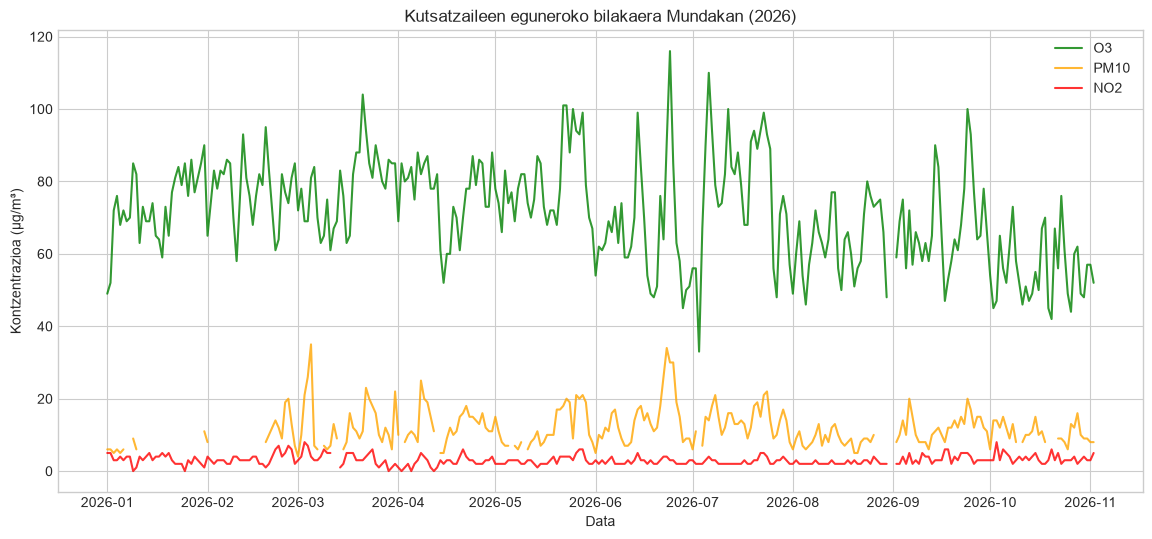

In [2]:
# 1. Kutsatzaile nagusien denbora-bilakaera
plt.figure(figsize=(14, 6))
plt.plot(df['Date'], df['O3 (µg/m3)'], label='O3', color='green', alpha=0.8)
plt.plot(df['Date'], df['PM10 (µg/m3)'], label='PM10', color='orange', alpha=0.8)
plt.plot(df['Date'], df['NO2 (µg/m3)'], label='NO2', color='red', alpha=0.8)
plt.title('Kutsatzaileen eguneroko bilakaera Mundakan (2026)')
plt.xlabel('Data')
plt.ylabel('Kontzentrazioa (µg/m³)')
plt.legend()
plt.show()

### 3.2. Kutsatzaileen banaketak

Kutsatzaile bakoitzaren balioak nola banatzen diren ikusteko histogramak egingo ditugu.

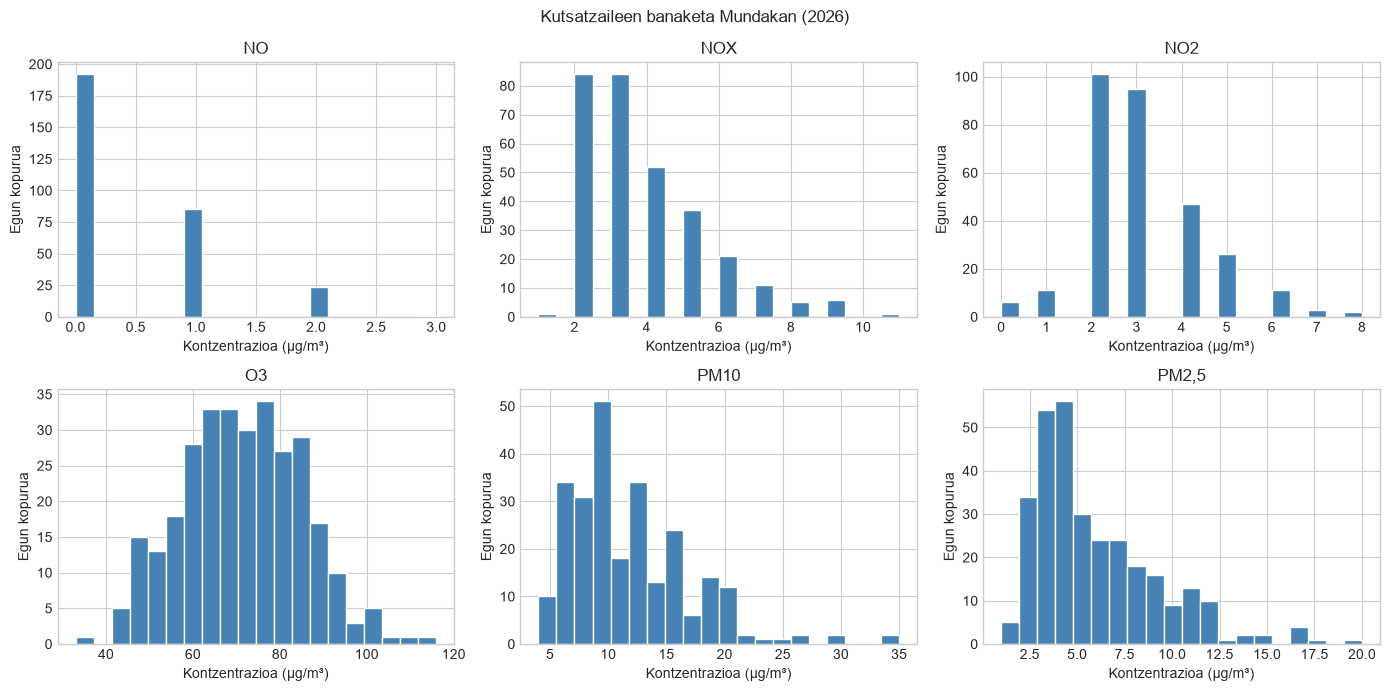

In [3]:
# Kutsatzaileen banaketak (histogramak)
kutsatzaile_zutabeak = ['NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'O3 (µg/m3)', 'PM10 (µg/m3)', 'PM2,5 (µg/m3)']
fig, ardatzak = plt.subplots(2, 3, figsize=(14, 7))
for ardatza, zutabea in zip(ardatzak.flatten(), kutsatzaile_zutabeak):
    ardatza.hist(df[zutabea].dropna(), bins=20, color='steelblue', edgecolor='white')
    ardatza.set_title(zutabea.split(' ')[0])
    ardatza.set_xlabel('Kontzentrazioa (µg/m³)')
    ardatza.set_ylabel('Egun kopurua')
plt.suptitle('Kutsatzaileen banaketa Mundakan (2026)')
plt.tight_layout()
plt.show()

Kutsatzaile gehienek balio baxu asko dituzte eta pikoak gutxi (ezkerrera makurtutako banaketak). NO, NOX eta NO2 oso balio baxuetan pilatzen dira, eta O3 da batezbestekoa altuena eta banaketa zabalena duena.

### 3.3. Ozonoaren (O3) eragin estazionala

Grafikoan O3 ikusten da nagusi, eta ez dirudi urtean zehar uniformea denik. Hilabeteko batezbestekoak kalkulatuko ditugu hori zenbakiekin baieztatzeko.

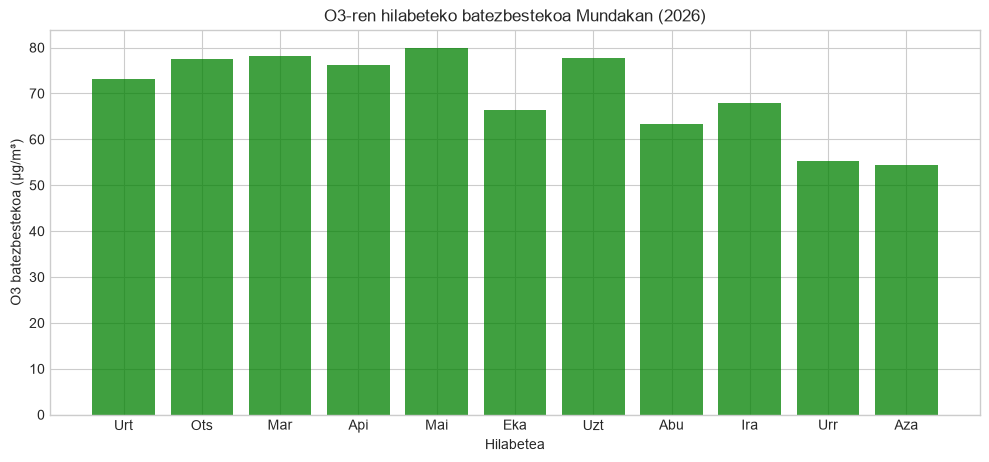

In [4]:
# Hilabeteko batezbestekoak (Month zutabea beranduago sortuko dugu behin betiko;
# hemen aldi baterako erabiltzen dugu grafikoa egiteko)
hilabete_izenak = ['Urt', 'Ots', 'Mar', 'Api', 'Mai', 'Eka', 'Uzt', 'Abu', 'Ira', 'Urr', 'Aza']
hilabetekoak = df.groupby(df['Date'].dt.month)[['O3 (µg/m3)', 'PM10 (µg/m3)', 'NO2 (µg/m3)']].mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(hilabete_izenak, hilabetekoak['O3 (µg/m3)'], color='green', alpha=0.75)
ax.set_title('O3-ren hilabeteko batezbestekoa Mundakan (2026)')
ax.set_xlabel('Hilabetea')
ax.set_ylabel('O3 batezbestekoa (µg/m³)')
plt.show()

### 3.4. Korrelazio matrizea

Kutsatzaileen artean erlazioak badauden aztertzeko korrelazio matrizea egingo dugu. Hau garrantzitsua da gero PCA aplikatuko dugulako: aldagai korrelatuak badira, dimentsioa murriztea zentzuzkoa da.

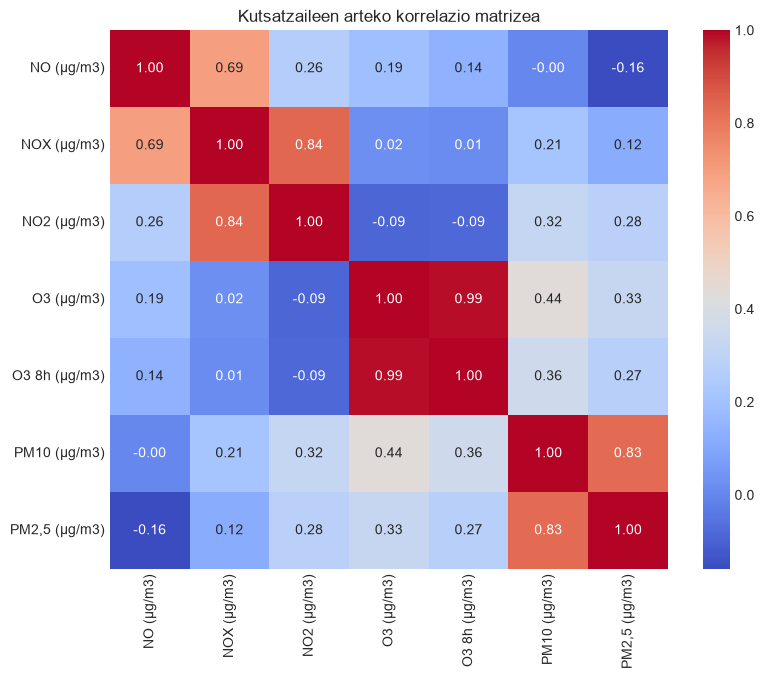

In [5]:
# 2. Korrelazio matrizea
plt.figure(figsize=(9, 7))
zutabe_zenbakizkoak = df.select_dtypes(include=[np.number]).columns
sns.heatmap(df[zutabe_zenbakizkoak].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Kutsatzaileen arteko korrelazio matrizea')
plt.show()

### 3.5. EDA-ren ondorioak

- **O3-ren efektu estazionala:** ozonoa udaberrian eta udan altuagoa da (maiatzean ≈ 80 µg/m³, uztailean ≈ 78 µg/m³) eta udazkenean nabarmen jaisten da (urrian eta azaroan ≈ 55 µg/m³). Zentzuzkoa da: O3 eguzki-erradiazioak eragindako erreakzio fotokimikoetan sortzen da, beraz eguzki-ordu gehiago dauden garaian handiagoa da. Ekainean batezbestekoa apur bat jaisten da, baina hilabete horretan ozono-pikorik handienetako bat ere ageri da (116 µg/m³, ekainaren 24an).
- **NO2 maila oso baxuak:** NO2-ren batezbestekoa ≈ 3 µg/m³ da eta maximoa 8 µg/m³. Mundaka kostaldeko herri txikia da, trafiko eta industria gutxirekin, eta itsasoko aireak kutsatzaileak sakabanatzen laguntzen du. Beraz, NO2 ez da arazo handi bat eremu honetan.
- **Korrelazio handiak:** `PM10` eta `PM2,5` oso lotuta daude (≈ 0,83), PM2,5 PM10-aren zati bat delako. Era berean, `NOX` eta `NO2` (≈ 0,84) eta `NOX` eta `NO` (≈ 0,69) ere lotuta daude, NOX bien batura delako. Informazio errepikatua dago, eta horrek PCA erabiltzea justifikatzen du.
- **O3 eta partikulak:** O3-k PM10-ekin korrelazio moderatua du (≈ 0,44), eta pikoak datu berdinetan batera ageri dira (ekainaren 23-25 inguruan, adibidez). Kausa zehatza ezin dugu datu hauekin ziurtatu, baina kutsadura-episodio puntual baten seinale izan daiteke.
- **Ia korrelaziorik ez O3 eta NOX artean (≈ 0,02):** ez dirudi hemen O3 tokiko NOx-aren mende dagoenik.
- **Datuen mugak:** eguneko neurketak eta estazio bakarra ditugu, beraz ezin ditugu ordu-patroiak (trafiko-puntak) edo estazioen arteko aldeak aztertu. Gainera, urte bakarreko datuak direnez, ezin dugu ziurtatu ikusitako urtaro-efektuak urtero errepikatzen direnik.

## 4. Garbiketa, balio hutsak eta *outlier*-ak

Balio hutsen kopurua 2. atalean ikusi dugu (`isnull().sum()`). Kontuan hartu: `31/08/2026` eta `01/09/2026` egunetan zutabe guztiak hutsik daude (neurketarik gabeko egunak).

### Erabakien justifikazioa

- **`O3 8h` zutabea kentzen dugu.** %31 huts ditu (>%30). Hainbeste daturen falta denez, mediana bidez betetzeak gehienetan asmatutako balioak sortuko lituzke, eta zutabeak ez luke informazio ona emango. Gainera, O3-ren 8 orduko batez bestekoa da, eta `O3` zutabearekin oso lotuta dago (informazio errepikatua), beraz galtzen dugun informazioa oso gutxi da.
- **Gainerako hutsak mediana bidez betetzen ditugu (`SimpleImputer(strategy='median')`).** Hutsak gutxi dira (%0,7-%1,3), eta `PM10` kasuan %16. Mediana batezbestekoa baino hobea da hemen, balio muturrekoek (kutsadura-pikoek) ez dutelako eragiten. Batezbestekoak, aldiz, pikoen aldera mugituko lituzke betetako balioak.
- **Outlier-ak ez ditugu ezabatzen.** Ingurumen-datuetan balio altuak (adibidez O3 = 116 µg/m³ edo PM10 = 35 µg/m³) **kutsadura-pikoak** dira, hau da, benetako gertaerak. Hauek ezabatzeak ereduari ezin izango lioke irakatsi benetan interesatzen zaiguna: kutsadura-episodioak detektatzea. Akats instrumentalen kasuan bakarrik ezabatu beharko genuke, eta hemen ez dago horren zantzurik (balioak fisikoki ahalezkoak dira).

Boxplot batekin *outlier*-ak ikusiko ditugu, ezabatu gabe.

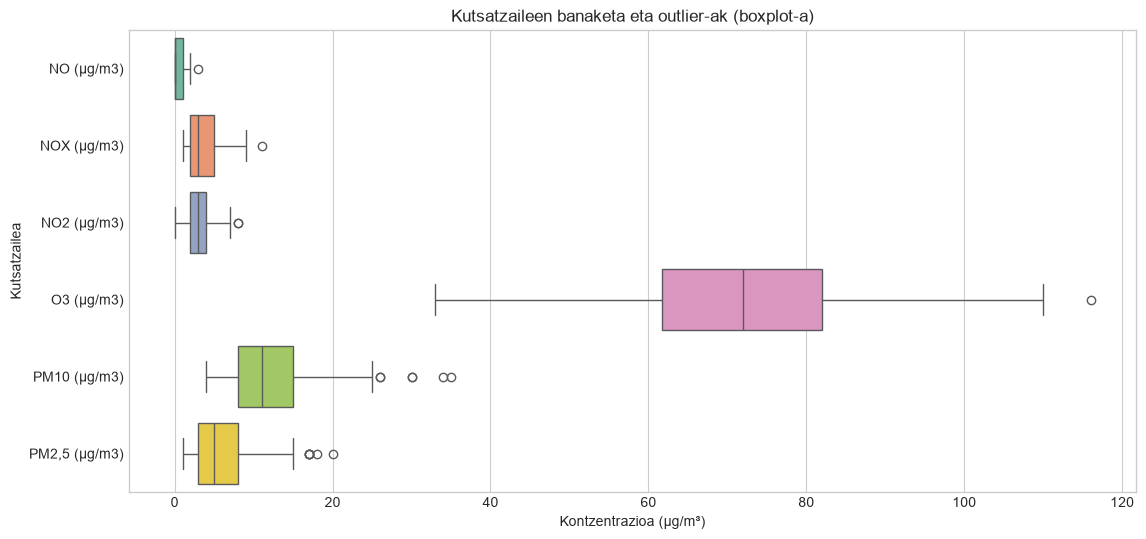

Outlier kopurua (IQR araua):
NO (µg/m3)       1
NOX (µg/m3)      1
NO2 (µg/m3)      2
O3 (µg/m3)       1
PM10 (µg/m3)     6
PM2,5 (µg/m3)    6
dtype: int64


In [6]:
# Outlier-ak ikusteko boxplot-a (ez dugu ezer ezabatzen)
plt.figure(figsize=(13, 6))
sns.boxplot(data=df[kutsatzaile_zutabeak], orient='h', palette='Set2')
plt.title('Kutsatzaileen banaketa eta outlier-ak (boxplot-a)')
plt.xlabel('Kontzentrazioa (µg/m³)')
plt.ylabel('Kutsatzailea')
plt.show()

# IQR araua: Q1 - 1,5*IQR azpitik edo Q3 + 1,5*IQR gainetik dauden balioak zenbatu
q1 = df[kutsatzaile_zutabeak].quantile(0.25)
q3 = df[kutsatzaile_zutabeak].quantile(0.75)
iqr = q3 - q1
outlierrak = (df[kutsatzaile_zutabeak] < q1 - 1.5 * iqr) | (df[kutsatzaile_zutabeak] > q3 + 1.5 * iqr)
print("Outlier kopurua (IQR araua):")
print(outlierrak.sum())

IQR arauak *outlier* gutxi detektatzen ditu: `PM10` eta `PM2,5` aldagaietan 6na, `NO2`-n 2 eta `NO`, `NOX` eta `O3` aldagaietan 1na. Esan bezala, **mantendu** egingo ditugu: kutsadura-pikoak dira.

## 5. Ezaugarri tenporalak (*Feature Engineering*)

Data bakarrik ez da egokia eredu batentzat, beraz data horretatik hiru aldagai tenporal ateratzen ditugu: `Month` (hilabetea, urtaroaren eragina jasotzeko), `DayOfWeek` (asteko eguna, trafiko-ereduak asteko egunen arabera aldatzen direlako) eta `DayOfYear` (urteko eguna). Ondoren `O3 8h` zutabea kenduko dugu, goian justifikatu bezala.

`DayOfYear` sortzen dugu baina ez dugu ezaugarri gisa sartzen, `Month`-ekin oso lotuta dagoelako eta informazio errepikatua litzatekeelako.

In [7]:
# 1. Ezaugarri tenporalak sortu
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['DayOfYear'] = df['Date'].dt.dayofyear

# 2. Hutsune gehiegi duen zutabea kendu (>%30)
if 'O3 8h (µg/m3)' in df.columns:
    df.drop(columns=['O3 8h (µg/m3)'], inplace=True)

# 3. Aldagai prediktoreak (X) eta helburua (y): PM10 aurreikusiko dugu
ezaugarri_zutabeak = ['NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'O3 (µg/m3)', 'PM2,5 (µg/m3)', 'Month', 'DayOfWeek']
helburua = 'PM10 (µg/m3)'
df_eredua = df.dropna(subset=[helburua])   # helburuan hutsik dutenak ezin dira erabili
X = df_eredua[ezaugarri_zutabeak]
y = df_eredua[helburua]

print("Entrenamendurako hautatutako ezaugarriak:")
print(X.head())
print(f"\nX-ren dimentsioak: {X.shape}, y-ren luzera: {len(y)}")

Entrenamendurako hautatutako ezaugarriak:
   NO (µg/m3)  NOX (µg/m3)  NO2 (µg/m3)  O3 (µg/m3)  PM2,5 (µg/m3)  Month  \
0         2.0          8.0          5.0        49.0            8.0      1   
1         2.0          9.0          5.0        52.0            5.0      1   
2         2.0          6.0          3.0        72.0            2.0      1   
3         2.0          6.0          3.0        76.0            3.0      1   
4         2.0          7.0          4.0        68.0            3.0      1   

   DayOfWeek  
0          3  
1          4  
2          5  
3          6  
4          0  

X-ren dimentsioak: (257, 7), y-ren luzera: 257


**Oharra:** `PM10` helburu gisa erabiliko dugu (`PM2,5`-ekin lotuta dago, ≈ 0,83), beraz ez dugu ezaugarrien artean sartzen. Helburuan balio hutsa duten errenkadak kendu ditugu.

## 6. Eraldaketa, *Pipeline*-a eta PCA

### 6.1. Zergatik Pipeline bat?

Aurreprozesamendua eta eredua Scikit-Learn-en `Pipeline` bakarrean lotzen ditugu:

1. **`SimpleImputer(strategy='median')`** – aldagai zenbakizkoetako balio hutsak medianaz betetzen ditu.
2. **`StandardScaler()`** – aldagai zenbakizkoak estandarizatzen ditu (batezbestekoa 0, desbideratzea 1). O3 (≈ 70 µg/m³) eta NO (≈ 0,5 µg/m³) eskala oso desberdinetan daude, eta PCA eskalarekiko sentikorra da.
3. **`OneHotEncoder`** – `Month` eta `DayOfWeek` aldagai kategorikotzat hartu eta *one-hot* kodetzen ditu (zenbaki baten ordez, kategoria bakoitzeko zutabe bat), hilabete 12 ez baita hilabete 6 baino "bi aldiz handiagoa".
4. **`PCA(n_components=0.95)`** – dimentsioa murrizten du, **bariantzaren %95** gordez.
5. **`LinearRegression()`** – eredu sinple bat, `PM10` aurreikusteko.

**Pipeline-aren abantaila nagusia *data leakage* saihestea da.** Imputer-ak, scaler-ak eta PCA-k datuetatik ikasten dute (mediana, batezbestekoa, osagaiak). Horregatik datuak lehenik *train*/*test* multzoetan banatzen ditugu eta `fit()` *train* multzoan bakarrik egiten dugu. *Test* multzoan eta datu berrietan `predict()` bakarrik erabiltzen da, *train*-eko parametro berekin.

**Banaketa kronologikoa.** Datuak denbora-serie bat dira eta egun jarraituak oso antzekoak dira. Ausazko banaketak *test*-eko egunen "bizilagunak" sartuko lituzke entrenamenduan, eta emaitzak baikorregiak aterako lirateke. Horregatik lehen %80 entrenatzeko eta azken %20 probatzeko erabiltzen ditugu, SAA zatian bezala. Urriko eta azaroko daturik ez dago entrenamenduan: `handle_unknown='ignore'` aukerari esker, *pipeline*-ak ez du errorerik ematen hilabete horiekin.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.base import clone
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

zutabe_zenbakizkoak = ['NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'O3 (µg/m3)', 'PM2,5 (µg/m3)']
zutabe_kategorikoak = ['Month', 'DayOfWeek']

# 1. Banaketa kronologikoa: lehen %80 train, azken %20 test (pipeline-a train multzoarekin bakarrik doituko dugu)
muga = int(len(X) * 0.8)
X_train, X_test = X.iloc[:muga], X.iloc[muga:]
y_train, y_test = y.iloc[:muga], y.iloc[muga:]
print(f"Train: {len(X_train)} errenkada | Test: {len(X_test)} errenkada")

# 2. Aurreprozesamendua: zenbakizkoak (imputer + scaler) eta kategorikoak (one-hot)
aurreprozesamendua = ColumnTransformer(transformers=[
    ('zenbakizkoak', Pipeline([('imputer', SimpleImputer(strategy='median')),
                               ('scaler', StandardScaler())]), zutabe_zenbakizkoak),
    ('kategorikoak', OneHotEncoder(handle_unknown='ignore', sparse_output=False), zutabe_kategorikoak)
])

# 3. Pipeline osoa: aurreprozesamendua + PCA (%95) + eredua
pipeline_osoa = Pipeline(steps=[
    ('aurreprozesamendua', aurreprozesamendua),
    ('pca', PCA(n_components=0.95)),
    ('eredua', LinearRegression())
])

# 4. Train multzoarekin doitu
pipeline_osoa.fit(X_train, y_train)

# 5. PCA-ren informazioa
pca = pipeline_osoa.named_steps['pca']
print(f"PCA osagai kopurua: {pca.n_components_}")
print(f"Bariantza azaldu metatua: {pca.explained_variance_ratio_.sum():.3f}")

# 6. Test multzoan (datu berriak) probatu
y_iragarpena = pipeline_osoa.predict(X_test)
print(f"\nMAE: {mean_absolute_error(y_test, y_iragarpena):.2f} µg/m³")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_iragarpena)):.2f} µg/m³")
print(f"R²: {r2_score(y_test, y_iragarpena):.3f}")

Train: 205 errenkada | Test: 52 errenkada
PCA osagai kopurua: 13
Bariantza azaldu metatua: 0.950

MAE: 1.96 µg/m³
RMSE: 2.67 µg/m³
R²: 0.220


### 6.2. PCA-ren eragina

Enuntziatuak PCA aplikatzeaz gain haren eragina aztertzea eskatzen du. Bi galdera egiten ditugu: zenbat osagai behar diren eta eredua hobetzen duen. *Pipeline* bera konparatzen dugu PCA-rik gabe eta bariantzaren %95, %90 eta %80 gordeta, `TimeSeriesSplit`-eko balidazioarekin (5 zati, *train* multzoan) eta *test* multzoan. Ausazko banaketaren R²-a ere erakusten dugu, konparaziorako bakarrik.

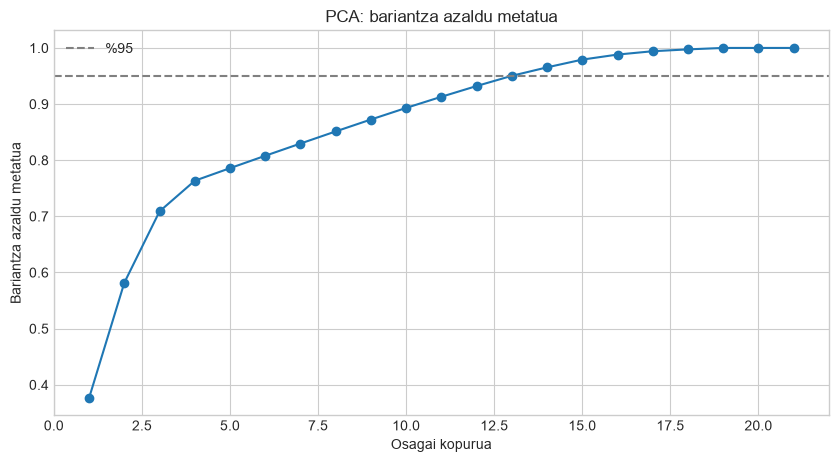

,Ezaugarriak,Balidazio RMSE,Desbideratzea,MAE,RMSE,R²,R² (ausazkoa)
Aukera,,,,,,,
PCA gabe,21,3.222,0.965,1.891,2.598,0.264,0.673
PCA %95,13,3.047,0.820,1.959,2.674,0.220,0.706
PCA %90,11,2.950,0.734,2.036,2.742,0.180,0.704
PCA %80,6,2.986,0.771,2.008,2.712,0.198,0.754


In [9]:
# 1. Bariantza metatua, osagai kopuruaren arabera (train multzoan)
X_train_eraldatua = clone(aurreprozesamendua).fit_transform(X_train)
metatua = np.cumsum(PCA().fit(X_train_eraldatua).explained_variance_ratio_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(metatua) + 1), metatua, marker='o')
plt.axhline(0.95, color='gray', linestyle='--', label='%95')
plt.title('PCA: bariantza azaldu metatua')
plt.xlabel('Osagai kopurua')
plt.ylabel('Bariantza azaldu metatua')
plt.legend()
plt.show()

# 2. Pipeline bera PCA-rekin eta gabe konparatu
def sortu_pipeline(bariantza):
    urratsak = [('aurreprozesamendua', clone(aurreprozesamendua))]
    if bariantza is not None:
        urratsak.append(('pca', PCA(n_components=bariantza)))
    urratsak.append(('eredua', LinearRegression()))
    return Pipeline(urratsak)

X_aus_tr, X_aus_te, y_aus_tr, y_aus_te = train_test_split(X, y, test_size=0.2, random_state=42)

emaitzak_pca = []
for izena, bariantza in [('PCA gabe', None), ('PCA %95', 0.95), ('PCA %90', 0.90), ('PCA %80', 0.80)]:
    balidazio_rmse = -cross_val_score(sortu_pipeline(bariantza), X_train, y_train, cv=TimeSeriesSplit(n_splits=5),
                                      scoring='neg_root_mean_squared_error')
    eredua = sortu_pipeline(bariantza).fit(X_train, y_train)
    iragarpena = eredua.predict(X_test)
    emaitzak_pca.append({
        'Aukera': izena,
        'Ezaugarriak': eredua[:-1].transform(X_train.head(1)).shape[1],
        'Balidazio RMSE': balidazio_rmse.mean(),
        'Desbideratzea': balidazio_rmse.std(),
        'MAE': mean_absolute_error(y_test, iragarpena),
        'RMSE': np.sqrt(mean_squared_error(y_test, iragarpena)),
        'R²': r2_score(y_test, iragarpena),
        'R² (ausazkoa)': r2_score(y_aus_te, sortu_pipeline(bariantza).fit(X_aus_tr, y_aus_tr).predict(X_aus_te))
    })
display(pd.DataFrame(emaitzak_pca).set_index('Aukera').round(3))

**Emaitzen irakurketa:**

- **PCA-k dimentsioa murrizten du:** bariantzaren %95 gordetzeko 21 ezaugarritik 13ra pasatzen gara (%38 gutxiago).
- **Balidazioan apur bat hobetzen du** (RMSE ≈ 3,22 → 3,05), baina aldea zatien arteko desbideratzea (≈ 0,8-1,0) baino txikiagoa da, beraz ez da hobekuntza argia.
- **Test multzoan ez du hobetzen** (R² ≈ 0,26 → 0,22): informazioaren zati bat galtzen da, eta eragina ia neutroa da.
- **Bariantza gutxiago gordetzeak ez du emaitza nabarmen aldatzen:** %90 eta %80 aukeren aldeak ere desbideratzea baino txikiagoak dira.
- **Ausazko banaketa baikorregia da:** R² ≈ 0,71 lortuko genuke PCA %95-ekin, kronologikoan ≈ 0,22 denean.

**Erabakia:** `PCA(0.95)` mantentzen dugu *pipeline* honetan, balidazioan apur bat hobea delako eta ezaugarri gutxiago uzten dituelako. Hala ere, ez da erabaki garrantzitsua, aldeak txikiak baitira. SAA zatian ez dugu PCA erabiltzen: Ridge-k aldagai korrelatuak erregularizazioarekin kudeatzen ditu, eta koefizienteak interpretatu nahi ditugu, PCA-k ezkutatuko lituzkeenak.

### 6.3. Esportazioa `.pkl` formatuan (`joblib`) eta datu berriekin froga

Pipeline osoa `joblib`-ekin gordetzen dugu. Fitxategi bakarrean gelditzen dira medianak, scaler-aren parametroak, *one-hot* kategoriak, PCA-ren osagaiak eta eredua. Horrela, **Jetson Nano**-n kargatu eta datu berriekin zuzenean erabil daiteke, ezer berriro kalkulatu gabe.

In [10]:
# 1. Pipeline-a diskoan gorde
joblib.dump(pipeline_osoa, 'pipeline_preprocesamiento_mundaka.pkl')
print("Pipeline-a ondo gorde da: 'pipeline_preprocesamiento_mundaka.pkl'")

# 2. Kargatu eta datu berri batzuekin probatu (test multzoko lehen 3 errenkadak)
pipeline_kargatua = joblib.load('pipeline_preprocesamiento_mundaka.pkl')
datu_berriak = X_test.head(3)
print("\nPM10 aurreikuspena (pipeline kargatua):", pipeline_kargatua.predict(datu_berriak).round(2))
print("PM10 benetako balioak:                 ", y_test.head(3).round(2).values)

Pipeline-a ondo gorde da: 'pipeline_preprocesamiento_mundaka.pkl'

PM10 aurreikuspena (pipeline kargatua): [6.38 8.21 7.8 ]
PM10 benetako balioak:                  [8. 8. 8.]


## 7. Entrenamendurako datu-multzo garbia

Azken emaitza gisa, datu-multzo garbia gordetzen dugu (`mundaka_garbia.csv`): aurreprozesamendua aplikatuta, baina PCA gabe, zutabeen esanahia ikusten jarrai dezagun. PCA *pipeline*-aren barruan aplikatzen da. Aurreprozesamendua *train* multzoarekin bakarrik doitu da.

Hasierako datuetatik datu-multzo garbira egindako eragiketak:

| # | Eragiketa | Zergatik | Emaitza |
|---|---|---|---|
| 1 | `MUNDAKA.csv` kargatu (`;`, `latin1`) | Fitxategiaren formatua | 306 errenkada, 8 zutabe |
| 2 | Datak bihurtu eta ordenatu | Fitxategia atzekoz aurrera dago | 2026-01-01 → 2026-11-02 |
| 3 | `Month` eta `DayOfWeek` sortu | Urtaroa eta asteko eguna jasotzeko | 2 ezaugarri berri |
| 4 | `O3 8h` kendu | %31 huts, eta `O3`-rekin oso lotuta (≈ 0,99) | Zutabe bat gutxiago |
| 5 | PM10 hutsik duten errenkadak kendu | Helburua ezin da asmatu | 257 errenkada (49 gutxiago) |
| 6 | *Outlier*-ak mantendu | Benetako kutsadura-pikoak dira | Ez da ezer ezabatu |
| 7 | Banaketa kronologikoa | Denbora-seriea da | 205 train, 52 test |
| 8 | Hutsak medianarekin bete | Pikoek ez dute eragiten | Hutsik gabe |
| 9 | Estandarizazioa | Eskala oso desberdinak | Batezbestekoa 0, desbideratzea 1 (*train*-en) |
| 10 | *One-hot* (`Month`, `DayOfWeek`) | Kategoriak dira, ez kantitateak | 21 ezaugarri guztira |

In [11]:
# Pipeline-ak train multzoarekin doitutako aurreprozesamendua datu guztiei aplikatu
aurre_doitua = pipeline_kargatua.named_steps['aurreprozesamendua']
izenak = [izena.split('__')[1] for izena in aurre_doitua.get_feature_names_out()]

df_garbia = pd.DataFrame(aurre_doitua.transform(X), columns=izenak, index=X.index)
df_garbia.insert(0, 'Date', df_eredua['Date'].dt.strftime('%Y-%m-%d'))
df_garbia.insert(1, 'Multzoa', ['train'] * len(X_train) + ['test'] * len(X_test))
df_garbia[helburua] = y
df_garbia.to_csv('mundaka_garbia.csv', index=False, encoding='utf-8')

print(f"Dimentsioak: {df_garbia.shape}")
print(f"Balio hutsak: {df_garbia.isnull().sum().sum()}")
print(df_garbia['Multzoa'].value_counts().to_dict())
display(df_garbia.head(3).round(2))

Dimentsioak: (257, 24)
Balio hutsak: 0
{'train': 205, 'test': 52}


,Date,Multzoa,NO (µg/m3),NOX (µg/m3),NO2 (µg/m3),O3 (µg/m3),"PM2,5 (µg/m3)",Month_1,Month_2,Month_3,...,Month_8,Month_9,DayOfWeek_0,DayOfWeek_1,DayOfWeek_2,DayOfWeek_3,DayOfWeek_4,DayOfWeek_5,DayOfWeek_6,PM10 (µg/m3)
0,2026-01-01,train,2.23,2.36,1.54,-1.84,0.37,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,6.0
1,2026-01-02,train,2.23,2.90,1.54,-1.62,-0.46,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,6.0
2,2026-01-03,train,2.23,1.28,0.05,-0.14,-1.28,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,5.0


## 8. Iturriak

- Datuak: [Open Data Euskadi](https://opendata.euskadi.eus), Euskadiko airearen kalitatearen sarea (Mundaka estazioa).
- [pandas dokumentazioa](https://pandas.pydata.org/docs/) eta [seaborn dokumentazioa](https://seaborn.pydata.org/).
- [scikit-learn dokumentazioa](https://scikit-learn.org/stable/): `Pipeline`, `ColumnTransformer`, `PCA`, `TimeSeriesSplit`.